In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Stats
from scipy.stats import ks_2samp, levene

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


In [3]:
def make_summary(df):
    """
    For each fish, compute the mean clone drift rate +/-
    1.96 * the standard error.
    """
    summary = (
        df.groupby('fish')['symlog10_r']
        .agg(['mean', 'std', 'count'])
        .reset_index()
    )
    summary['se'] = summary['std'] / summary['count']**0.5
    summary['ci_low'] = summary['mean'] - 1.96 * summary['se']
    summary['ci_high'] = summary['mean'] + 1.96 * summary['se']
    return summary

exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

# Filter scenarios
df2 = df.query('scenario.isin([@exp_scenario, @sim_scenario])')
exp_df = df.query('scenario == @exp_scenario')
sim_df = df.query('scenario == @sim_scenario and duplicate == 0')

exp_summary = make_summary(exp_df)
sim_summary = make_summary(sim_df)

In [4]:
# exp_summary_sorted = exp_summary.sort_values(by='mean')
fish_order = np.array(exp_summary.sort_values(by='mean', ignore_index=True)['fish'])
sim_summary_sorted = sim_summary.set_index('fish').reindex(fish_order)

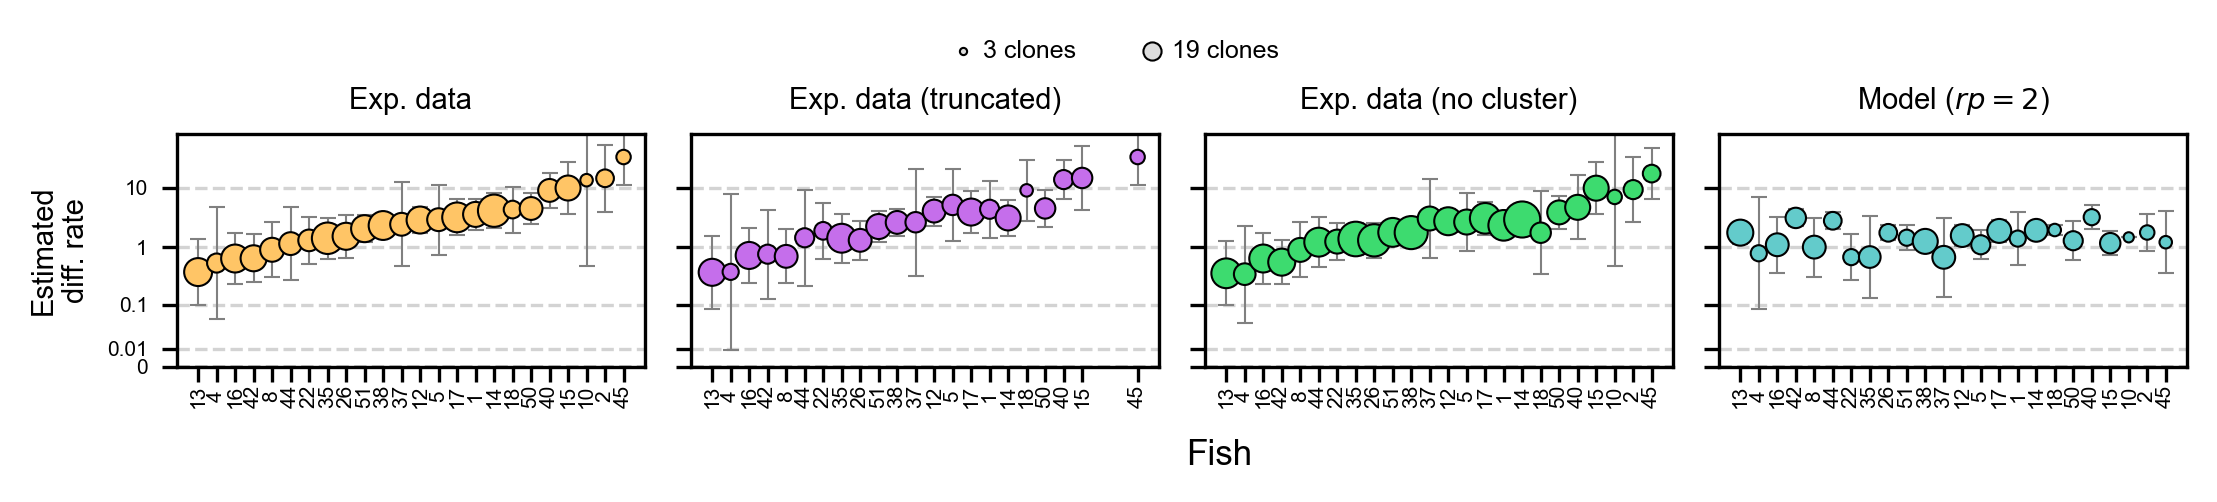

In [5]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

supplement_mode = True
if supplement_mode:
    scenarios = ['full_pipeline', 'full_pipeline_trunc', 'no_collapse', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Exp. data (truncated)', 'Exp. data (no cluster)', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 4, figsize = (7.4, 1.5), dpi = 300, sharey = True)
    filepath = os.path.join('images', 'anova_supplement.svg')
else:
    scenarios = ['full_pipeline', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 2, figsize = (3.7, 2), dpi = 300, sharey = True)
    filepath = os.path.join('images', 'anova.svg')

palette = {
    'Model ($rp=0$)': hue(0),
    'Model ($rp=2$)': hue(2),
    'Exp. data': exp_hue,
    'Exp. data (truncated)': trunc_hue,
    'Exp. data (no cluster)': no_collapse_hue,
}

# Shared y-axis formatting
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)

for i, (scenario, label) in enumerate(zip(
    scenarios, labels
)):
    df2 = df.query('scenario == @scenario and duplicate == 0')
    summary = make_summary(df2)
    summary_sorted = summary.set_index('fish').reindex(fish_order)#.reset_index(drop=True)
    
    xpos = np.arange(len(summary_sorted))
    not_na = ~summary_sorted['mean'].isna().to_numpy()

    ax[i].errorbar(
        xpos, summary_sorted['mean'],
        yerr = [summary_sorted['mean'] - summary_sorted['ci_low'], summary_sorted['ci_high'] - summary_sorted['mean']],
        fmt = 'none', ecolor = 'gray', capsize = 2, lw = 0.5, capthick = 0.5
    )

    sizes = 3 * summary_sorted['count']
    ax[i].scatter(
        xpos, summary_sorted['mean'],
        s = sizes, facecolor = palette[label], edgecolor = 'black', zorder = 3, lw = 0.5
    )

    ax[i].axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax[i].set_title(label)
    ax[i].set_xticks(xpos[not_na])
    ax[i].set_xticklabels(summary_sorted[not_na].index, size=5, rotation=90, va='center')
    ax[i].grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')

    ax[i].set_yticks(tick_symlog)
    ax[i].set_yticklabels([str(r) for r in tick_r])
    ax[i].set_ylim([0, 3.9])

ax[0].set_ylabel('Estimated\ndiff. rate')

fig.supxlabel('Fish', x=0.55, y = 0.07)

# Custom legend handles
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#dddddd',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = fig.legend(
    legend_handles,
    [f'{size} clones' for size in sizes],
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=3, 
    fontsize=6,
    handletextpad=-0.2
)

plt.tight_layout()
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

In [6]:
dep_var = 'symlog10_r'

In [7]:
def residuals(group):
    return group[dep_var] - group[dep_var].mean()

def between_within_variance(df, exp_scenario, sim_scenario, duplicate):
    df2 = df.query('scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == @duplicate)')

    # Fish-level means
    fish_means = df2.groupby(['scenario','fish'])[dep_var].mean().reset_index()
    
    exp_means = fish_means.loc[fish_means['scenario'] == exp_scenario, dep_var]
    sim_means = fish_means.loc[fish_means['scenario'] == sim_scenario, dep_var]
    
    # Between-fish variance test
    between_test = levene(exp_means, sim_means)
    
    resids = df2.groupby(['scenario','fish']).apply(residuals, include_groups = False).reset_index(level = [0,1])
    
    exp_resids = resids.loc[resids['scenario'] == exp_scenario, dep_var]
    sim_resids = resids.loc[resids['scenario'] == sim_scenario, dep_var]
    
    # Within-fish variance test
    within_test = levene(exp_resids, sim_resids)

    return between_test, within_test

In [8]:
between_test, within_test = between_within_variance(df, 'full_pipeline', 'r36_rp2_mimic', 0)
print(f"Between-fish variance test: {between_test.statistic:.2f} (p = {between_test.pvalue:.3e}).")
print(f"Within-fish variance test: {within_test.statistic:.2f} (p = {within_test.pvalue:.3e}).")

Between-fish variance test: 12.81 (p = 8.265e-04).
Within-fish variance test: 22.21 (p = 3.262e-06).


In [9]:
exp_scenario = 'full_pipeline'

rows = []
for d in df['duplicate'].unique():
    # print(f'Duplicate {d}:')
    between_test, within_test = between_within_variance(df, exp_scenario, sim_scenario, d)
    row = {'duplicate': d, 'between p': between_test.pvalue, 'within p': within_test.pvalue}
    rows.append(row)
    # print(f" - Between-fish variance test: {between_test.statistic:.2f} (p = {between_test.pvalue:.3e}).")
    # print(f" - Within-fish variance test: {within_test.statistic:.2f} (p = {within_test.pvalue:.3e}).")

results_df = pd.DataFrame(rows)
results_df

,duplicate,between p,within p
0,0,0.000826,3.261541e-06
1,1,0.012149,2.331318e-07
2,2,0.001571,3.174855e-08
3,3,0.002914,1.302729e-07
4,4,0.026403,1.245163e-07
5,5,0.170668,1.299985e-06
6,6,0.015570,1.693026e-07
7,7,0.020727,1.686498e-04
8,8,0.004196,5.114523e-07
9,9,0.125457,2.733216e-07
